In [30]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

raiz_projeto = str(Path().resolve().parent)
if raiz_projeto not in sys.path:
    sys.path.append(raiz_projeto)

from src.data_loader import SEEDS_TREINO, fixar_sementes, preparar_dados_pytorch
from src.metrics import calcular_metricas_classificacao, calcular_metricas_regressao
from src.models import MLP
from src.train import treinar

os.makedirs("../reports/tables", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [31]:
# 1. Carregamento dos dados (mesma divisão 80/20 e random_state=42)
fixar_sementes(42)
loaders_reg, scaler_X_reg, scaler_y_reg, n_features_reg = preparar_dados_pytorch(
    caminho_csv="../data/processed/dataset_regression.csv",
    target_col="term_gpa",
    tipo="reg",
    batch_size=32,
)

loaders_cls, scaler_X_cls, _, n_features_cls = preparar_dados_pytorch(
    caminho_csv="../data/processed/dataset_classification.csv",
    target_col="gpa_category_encoded",
    tipo="class",
    batch_size=32,
)

In [32]:
def obter_previsoes(modelo: nn.Module, dataset, tarefa: str):
    """Gera previsões em modo eval() sobre um dataset inteiro."""
    dl = DataLoader(dataset, batch_size=len(dataset), shuffle=False)
    modelo.eval()
    with torch.inference_mode():
        xb, yb = next(iter(dl))
        saida = modelo(xb.to(device)).cpu().numpy().ravel()
        reais = yb.numpy().ravel()

    if tarefa == "regressao":
        preds = scaler_y_reg.inverse_transform(saida.reshape(-1, 1)).ravel()
        reais_orig = (
            scaler_y_reg.inverse_transform(reais.reshape(-1, 1)).ravel()
            if np.abs(reais.mean()) < 1.0
            else reais
        )
        return reais_orig, preds
    else:
        probs = 1.0 / (1.0 + np.exp(-np.clip(saida, -50, 50)))
        return reais.astype(int), probs

In [33]:
def avaliar_treino_e_teste(tarefa: str, nome_modelo: str, hidden: tuple, lr: float):
    """Treina nas sementes e calcula métricas no treino, teste e gap de generalização."""
    loaders = loaders_reg if tarefa == "regressao" else loaders_cls
    in_dim = n_features_reg if tarefa == "regressao" else n_features_cls
    loss_fn = nn.MSELoss() if tarefa == "regressao" else nn.BCEWithLogitsLoss()

    registros_sementes = []
    melhor_modelo = None
    melhor_val = float("inf")
    artefatos_melhor = None

    for seed in SEEDS_TREINO:
        fixar_sementes(seed)
        modelo = MLP(in_dim=in_dim, out_dim=1, hidden=hidden, activation="ReLU", dropout=0.0)
        otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)

        hist = treinar(
            modelo=modelo,
            dl_tr=loaders["train"],
            dl_val=loaders["val"],
            loss_fn=loss_fn,
            otimizador=otimizador,
            n_epocas=200,
            paciencia=20,
            device=device,
        )

        y_tr, pred_tr = obter_previsoes(modelo, loaders["train"].dataset, tarefa)
        y_te, pred_te = obter_previsoes(modelo, loaders["test"].dataset, tarefa)

        if tarefa == "regressao":
            m_tr = calcular_metricas_regressao(y_tr, pred_tr)
            m_te = calcular_metricas_regressao(y_te, pred_te)
            reg = {
                **{f"{k}_Treino": v for k, v in m_tr.items()},
                **{f"{k}_Teste": v for k, v in m_te.items()},
                "Gap_RMSE (Teste-Treino)": m_te["RMSE"] - m_tr["RMSE"],
                "Gap_R2 (Treino-Teste)": m_tr["R2"] - m_te["R2"],
            }
        else:
            m_tr = calcular_metricas_classificacao(y_tr, pred_tr)
            m_te = calcular_metricas_classificacao(y_te, pred_te)
            reg = {
                **{f"{k}_Treino": v for k, v in m_tr.items()},
                **{f"{k}_Teste": v for k, v in m_te.items()},
                "Gap_F1 (Treino-Teste)": m_tr["F1"] - m_te["F1"],
                "Gap_Acc (Treino-Teste)": m_tr["Acuracia"] - m_te["Acuracia"],
            }

        registros_sementes.append(reg)

        if min(hist["val"]) < melhor_val:
            melhor_val = min(hist["val"])
            melhor_modelo = modelo
            artefatos_melhor = (y_te, pred_te)

    df_s = pd.DataFrame(registros_sementes)
    resumo = {
        "Tarefa": tarefa,
        "Modelo": nome_modelo,
        "Arquitetura": str(hidden),
        "LR": lr,
        "Parametros": melhor_modelo.contar_parametros(),
    }
    for col in df_s.columns:
        resumo[f"{col}_media"] = float(df_s[col].mean())
        resumo[f"{col}_std"] = float(df_s[col].std())
        resumo[col] = f"{df_s[col].mean():.4f} ± {df_s[col].std():.4f}"

    return resumo, melhor_modelo, artefatos_melhor

In [34]:
# 2. Execução para Baseline e Modelo Otimizado em ambas as tarefas
res_reg_base, _, _ = avaliar_treino_e_teste("regressao", "MLP Baseline", (32, 32), 1e-3)
res_reg_opt, mod_reg_opt, dados_te_reg = avaliar_treino_e_teste("regressao", "MLP Otimizada", (128, 128), 1e-2)

res_cls_base, _, _ = avaliar_treino_e_teste("classificacao", "MLP Baseline", (32, 32), 1e-3)
res_cls_opt, mod_cls_opt, dados_te_cls = avaliar_treino_e_teste("classificacao", "MLP Otimizada", (128, 128), 1e-3)

# 3. Exportação da tabela-resumo final
df_resumo_final = pd.DataFrame([res_reg_base, res_reg_opt, res_cls_base, res_cls_opt])
df_resumo_final.to_csv("../reports/tables/resumo_final.csv", index=False)

print("=== TABELA FINAL — REGRESSÃO (TREINO vs. TESTE E GAP) ===")
cols_reg = ["Modelo", "Arquitetura", "LR", "RMSE_Treino", "RMSE_Teste", "Gap_RMSE (Teste-Treino)", "MAE_Teste", "R2_Treino", "R2_Teste", "MAPE (%)_Teste"]
display(df_resumo_final[df_resumo_final["Tarefa"] == "regressao"][cols_reg])

print("\n=== TABELA FINAL — CLASSIFICAÇÃO (TREINO vs. TESTE E GAP) ===")
cols_cls = ["Modelo", "Arquitetura", "LR", "Acuracia_Treino", "Acuracia_Teste", "F1_Treino", "F1_Teste", "Gap_F1 (Treino-Teste)", "Precisao_Teste", "Recall_Teste", "ROC_AUC_Teste", "PR_AUC_Teste"]
display(df_resumo_final[df_resumo_final["Tarefa"] == "classificacao"][cols_cls])

=== TABELA FINAL — REGRESSÃO (TREINO vs. TESTE E GAP) ===


,Modelo,Arquitetura,LR,RMSE_Treino,RMSE_Teste,Gap_RMSE (Teste-Treino),MAE_Teste,R2_Treino,R2_Teste,MAPE (%)_Teste
0,MLP Baseline,"(32, 32)",0.001,0.3409 ± 0.0038,0.3890 ± 0.0047,0.0481 ± 0.0071,0.2827 ± 0.0037,0.4698 ± 0.0117,0.4204 ± 0.0139,9.4568 ± 0.1379
1,MLP Otimizada,"(128, 128)",0.010,0.3413 ± 0.0126,0.4113 ± 0.0184,0.0700 ± 0.0302,0.3029 ± 0.0116,0.4679 ± 0.0387,0.3509 ± 0.0595,9.8009 ± 0.2997



=== TABELA FINAL — CLASSIFICAÇÃO (TREINO vs. TESTE E GAP) ===


,Modelo,Arquitetura,LR,Acuracia_Treino,Acuracia_Teste,F1_Treino,F1_Teste,Gap_F1 (Treino-Teste),Precisao_Teste,Recall_Teste,ROC_AUC_Teste,PR_AUC_Teste
2,MLP Baseline,"(32, 32)",0.001,0.7615 ± 0.0063,0.7762 ± 0.0087,0.7695 ± 0.0047,0.7880 ± 0.0070,-0.0185 ± 0.0075,0.7596 ± 0.0122,0.8187 ± 0.0086,0.8484 ± 0.0062,0.8581 ± 0.0050
3,MLP Otimizada,"(128, 128)",0.001,0.7500 ± 0.0071,0.7714 ± 0.0118,0.7603 ± 0.0064,0.7864 ± 0.0100,-0.0261 ± 0.0130,0.7490 ± 0.0168,0.8281 ± 0.0191,0.8489 ± 0.0039,0.8572 ± 0.0049


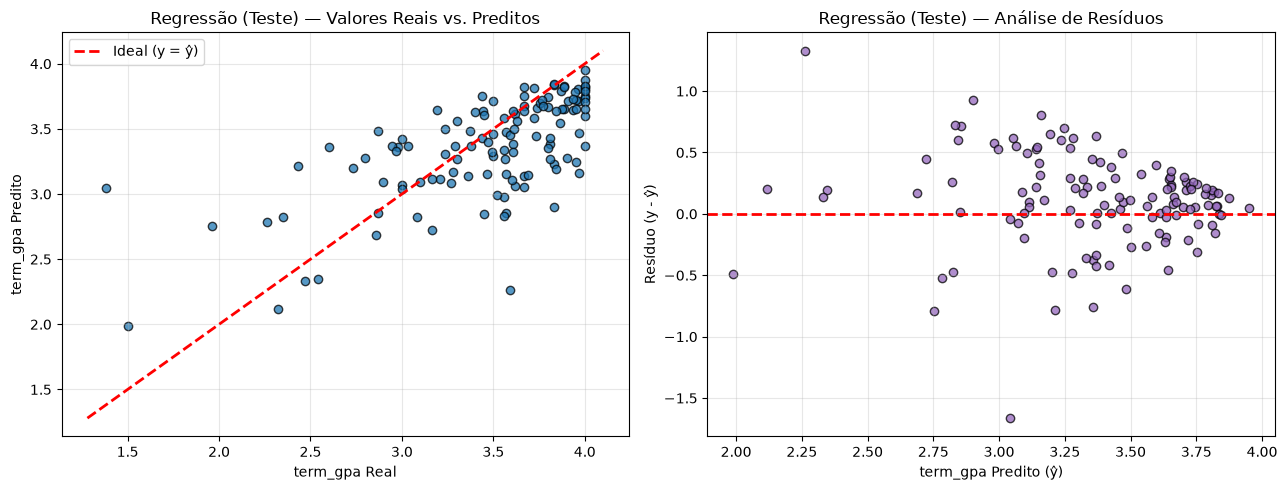

In [35]:
# 1. Gráficos de Diagnóstico — Regressão (Teste)
y_te_reg, y_pred_reg = dados_te_reg
residuos_reg = y_te_reg - y_pred_reg

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_te_reg, y_pred_reg, alpha=0.75, edgecolors="k", color="tab:blue")
lim_min = min(y_te_reg.min(), y_pred_reg.min()) - 0.1
lim_max = max(y_te_reg.max(), y_pred_reg.max()) + 0.1
axes[0].plot([lim_min, lim_max], [lim_min, lim_max], "r--", lw=2, label="Ideal (y = ŷ)")
axes[0].set_title("Regressão (Teste) — Valores Reais vs. Preditos")
axes[0].set_xlabel("term_gpa Real")
axes[0].set_ylabel("term_gpa Predito")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_pred_reg, residuos_reg, alpha=0.75, edgecolors="k", color="tab:purple")
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Regressão (Teste) — Análise de Resíduos")
axes[1].set_xlabel("term_gpa Predito (ŷ)")
axes[1].set_ylabel("Resíduo (y - ŷ)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/diagnostico_regressao_teste.png", dpi=150)
plt.show()

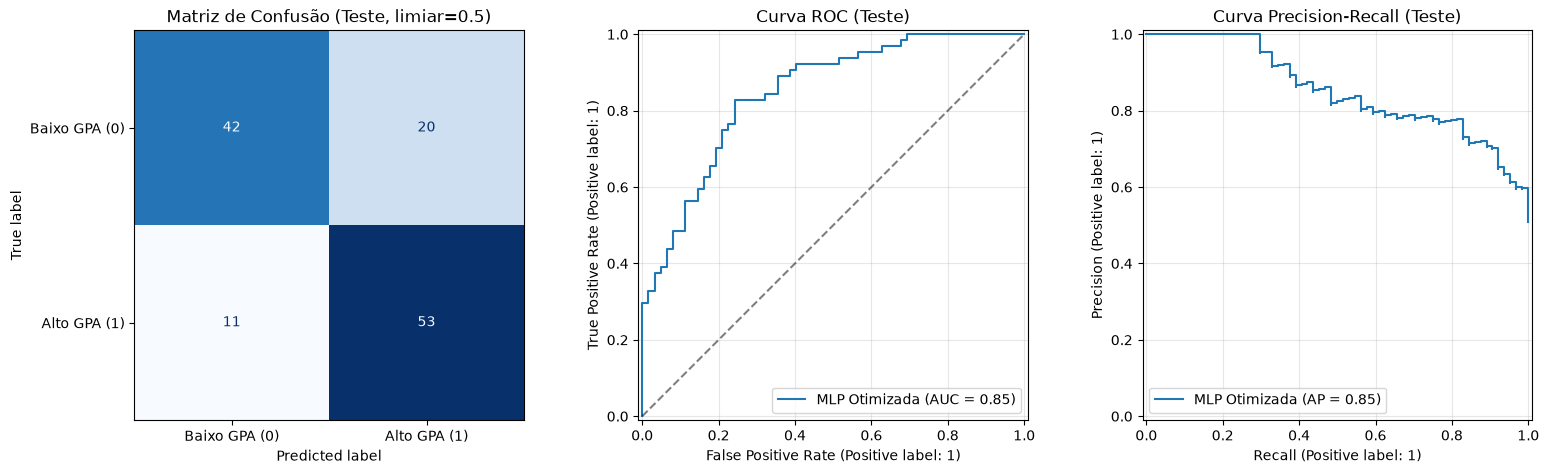

In [36]:
# 2. Gráficos de Diagnóstico — Classificação (Teste)
y_te_cls, y_prob_cls = dados_te_cls
y_pred_bin_cls = (y_prob_cls >= 0.5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

cm = confusion_matrix(y_te_cls, y_pred_bin_cls)
ConfusionMatrixDisplay(cm, display_labels=["Baixo GPA (0)", "Alto GPA (1)"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("Matriz de Confusão (Teste, limiar=0.5)")

RocCurveDisplay.from_predictions(y_te_cls, y_prob_cls, ax=axes[1], name="MLP Otimizada")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_title("Curva ROC (Teste)")
axes[1].grid(True, alpha=0.3)

PrecisionRecallDisplay.from_predictions(y_te_cls, y_prob_cls, ax=axes[2], name="MLP Otimizada")
axes[2].set_title("Curva Precision-Recall (Teste)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/diagnostico_classificacao_teste.png", dpi=150)
plt.show()

In [37]:
# 3. Estudo de Limiar de Decisão (ajustado apenas na VALIDAÇÃO)
y_val_cls, y_prob_val_cls = obter_previsoes(mod_cls_opt, loaders_cls["val"].dataset, "classificacao")
limiares = np.linspace(0.10, 0.90, 81)
f1s_val = [f1_score(y_val_cls, (y_prob_val_cls >= t).astype(int), zero_division=0) for t in limiares]

melhor_idx = int(np.argmax(f1s_val))
melhor_limiar = float(limiares[melhor_idx])
y_pred_te_ajustado = (y_prob_cls >= melhor_limiar).astype(int)

print(f"Melhor limiar na Validação: {melhor_limiar:.2f} (F1 Val = {f1s_val[melhor_idx]:.4f})")
print(f"No Teste com limiar padrão (0.50): F1 = {f1_score(y_te_cls, y_pred_bin_cls):.4f} | "
      f"Precisão = {precision_score(y_te_cls, y_pred_bin_cls):.4f} | Recall = {recall_score(y_te_cls, y_pred_bin_cls):.4f}")
print(f"No Teste com limiar ajustado ({melhor_limiar:.2f}): F1 = {f1_score(y_te_cls, y_pred_te_ajustado):.4f} | "
      f"Precisão = {precision_score(y_te_cls, y_pred_te_ajustado):.4f} | Recall = {recall_score(y_te_cls, y_pred_te_ajustado):.4f}")

Melhor limiar na Validação: 0.59 (F1 Val = 0.7912)
No Teste com limiar padrão (0.50): F1 = 0.7737 | Precisão = 0.7260 | Recall = 0.8281
No Teste com limiar ajustado (0.59): F1 = 0.7619 | Precisão = 0.7742 | Recall = 0.7500


In [38]:
xb_test, yb_test = next(iter(loaders_reg["test"]))
print("Min/Max direto do DataLoader (yb_test):", yb_test.min().item(), yb_test.max().item())
print("Min/Max após inverse_transform:", scaler_y_reg.inverse_transform(yb_test.numpy().reshape(-1, 1)).min(),
      scaler_y_reg.inverse_transform(yb_test.numpy().reshape(-1, 1)).max())

Min/Max direto do DataLoader (yb_test): 1.5 4.0
Min/Max após inverse_transform: 4.168087 5.3384285


In [39]:
# 1. Carregamento das bases completas para K-Fold (com embaralhamento estratificado/aleatório)
df_reg_full = pd.read_csv("../data/processed/dataset_regression.csv")
X_full_reg = df_reg_full.drop(columns=["term_gpa"]).to_numpy(dtype=np.float32)
y_full_reg = df_reg_full["term_gpa"].to_numpy(dtype=np.float32)

df_cls_full = pd.read_csv("../data/processed/dataset_classification.csv")
X_full_cls = df_cls_full.drop(columns=["gpa_category_encoded"]).to_numpy(dtype=np.float32)
y_full_cls = df_cls_full["gpa_category_encoded"].to_numpy(dtype=int)

In [40]:
def executar_kfold(tarefa: str, X: np.ndarray, y: np.ndarray, hidden: tuple, lr: float, k: int = 5):
    """Executa K-Fold ajustando StandardScaler dentro de cada fold (sem vazamento)."""
    splitter = KFold(n_splits=k, shuffle=True, random_state=42) if tarefa == "regressao" else StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    loss_fn = nn.MSELoss() if tarefa == "regressao" else nn.BCEWithLogitsLoss()

    metricas_folds = []

    for fold_idx, (idx_tr, idx_va) in enumerate(splitter.split(X, y), start=1):
        fixar_sementes(42 + fold_idx)

        scaler_x = StandardScaler()
        X_tr_s = scaler_x.fit_transform(X[idx_tr])
        X_va_s = scaler_x.transform(X[idx_va])

        if tarefa == "regressao":
            scaler_y = StandardScaler()
            y_tr_s = scaler_y.fit_transform(y[idx_tr].reshape(-1, 1)).ravel()
            y_va_s = scaler_y.transform(y[idx_va].reshape(-1, 1)).ravel()
            t_y_tr = torch.tensor(y_tr_s, dtype=torch.float32)
            t_y_va = torch.tensor(y_va_s, dtype=torch.float32)
        else:
            t_y_tr = torch.tensor(y[idx_tr], dtype=torch.float32)
            t_y_va = torch.tensor(y[idx_va], dtype=torch.float32)

        dl_tr = DataLoader(TensorDataset(torch.tensor(X_tr_s), t_y_tr), batch_size=32, shuffle=True)
        dl_va = DataLoader(TensorDataset(torch.tensor(X_va_s), t_y_va), batch_size=len(idx_va), shuffle=False)

        modelo = MLP(in_dim=X.shape[1], out_dim=1, hidden=hidden, activation="ReLU", dropout=0.0)
        otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)

        treinar(
            modelo=modelo,
            dl_tr=dl_tr,
            dl_val=dl_va,
            loss_fn=loss_fn,
            otimizador=otimizador,
            n_epocas=200,
            paciencia=20,
            device=device,
        )

        modelo.eval()
        with torch.inference_mode():
            saida_va = modelo(torch.tensor(X_va_s).to(device)).cpu().numpy().ravel()

        if tarefa == "regressao":
            preds_orig = scaler_y.inverse_transform(saida_va.reshape(-1, 1)).ravel()
            m = calcular_metricas_regressao(y[idx_va], preds_orig)
        else:
            probs_orig = 1.0 / (1.0 + np.exp(-np.clip(saida_va, -50, 50)))
            m = calcular_metricas_classificacao(y[idx_va], probs_orig)

        m["Fold"] = fold_idx
        metricas_folds.append(m)

    df_f = pd.DataFrame(metricas_folds)
    resumo = {"Tarefa": tarefa, "Modelo": f"MLP {hidden}", "K_Folds": k}
    for col in [c for c in df_f.columns if c != "Fold"]:
        resumo[f"{col}_media"] = float(df_f[col].mean())
        resumo[f"{col}_std"] = float(df_f[col].std())
        resumo[col] = f"{df_f[col].mean():.4f} ± {df_f[col].std():.4f}"

    return resumo, df_f

In [41]:
res_kf_reg, folds_reg = executar_kfold("regressao", X_full_reg, y_full_reg, hidden=(128, 128), lr=1e-2, k=5)
res_kf_cls, folds_cls = executar_kfold("classificacao", X_full_cls, y_full_cls, hidden=(128, 128), lr=1e-3, k=5)

df_kfold_resumo = pd.DataFrame([res_kf_reg, res_kf_cls])
df_kfold_resumo.to_csv("../reports/tables/validacao_cruzada_kfold.csv", index=False)

print("=== VALIDAÇÃO CRUZADA 5-FOLD — REGRESSÃO ===")
display(df_kfold_resumo[df_kfold_resumo["Tarefa"] == "regressao"][["Modelo", "K_Folds", "RMSE", "MAE", "R2", "MAPE (%)"]])

print("\n=== VALIDAÇÃO CRUZADA 5-FOLD — CLASSIFICAÇÃO ===")
display(df_kfold_resumo[df_kfold_resumo["Tarefa"] == "classificacao"][["Modelo", "K_Folds", "Acuracia", "Precisao", "Recall", "F1", "ROC_AUC", "PR_AUC"]])

=== VALIDAÇÃO CRUZADA 5-FOLD — REGRESSÃO ===


,Modelo,K_Folds,RMSE,MAE,R2,MAPE (%)
0,"MLP (128, 128)",5,0.3800 ± 0.0397,0.2709 ± 0.0271,0.4175 ± 0.0539,9.7290 ± 2.1904



=== VALIDAÇÃO CRUZADA 5-FOLD — CLASSIFICAÇÃO ===


,Modelo,K_Folds,Acuracia,Precisao,Recall,F1,ROC_AUC,PR_AUC
1,"MLP (128, 128)",5,0.7683 ± 0.0397,0.7705 ± 0.0140,0.7737 ± 0.0871,0.7705 ± 0.0490,0.8401 ± 0.0376,0.8389 ± 0.0287
